# SiPM count comparison — A+t1+t2+t3 ExtraTrees
Run the single cell below to reproduce both figures and save PNG + vector PDF copies. Edit `BASE` for your data and `OUT` for exports. Requires NumPy and Matplotlib (`%pip install numpy matplotlib` if missing).

Reads the six `output_edge0_spatiotemporal` … `output_edge5_spatiotemporal` folders without modifying them. SiPM count = 4 + 4 × edge index. Main summaries and timing scans remain separate; jitter is Gaussian σ, and no uncertainty estimates are supplied.

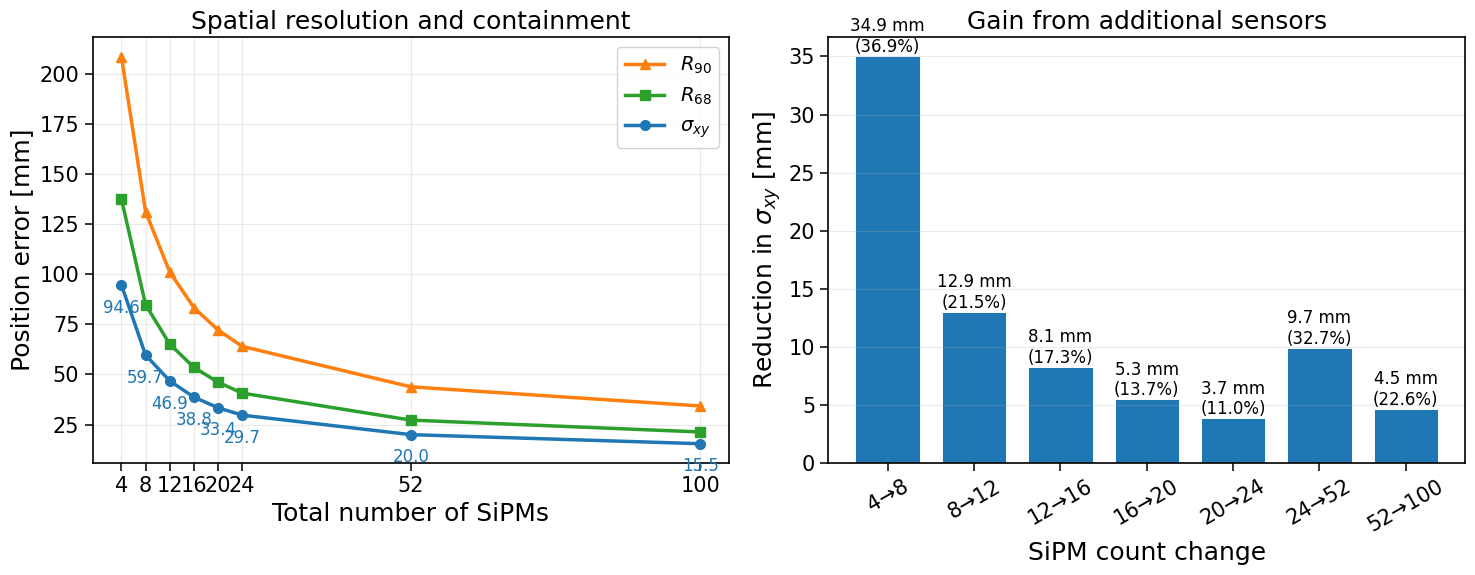

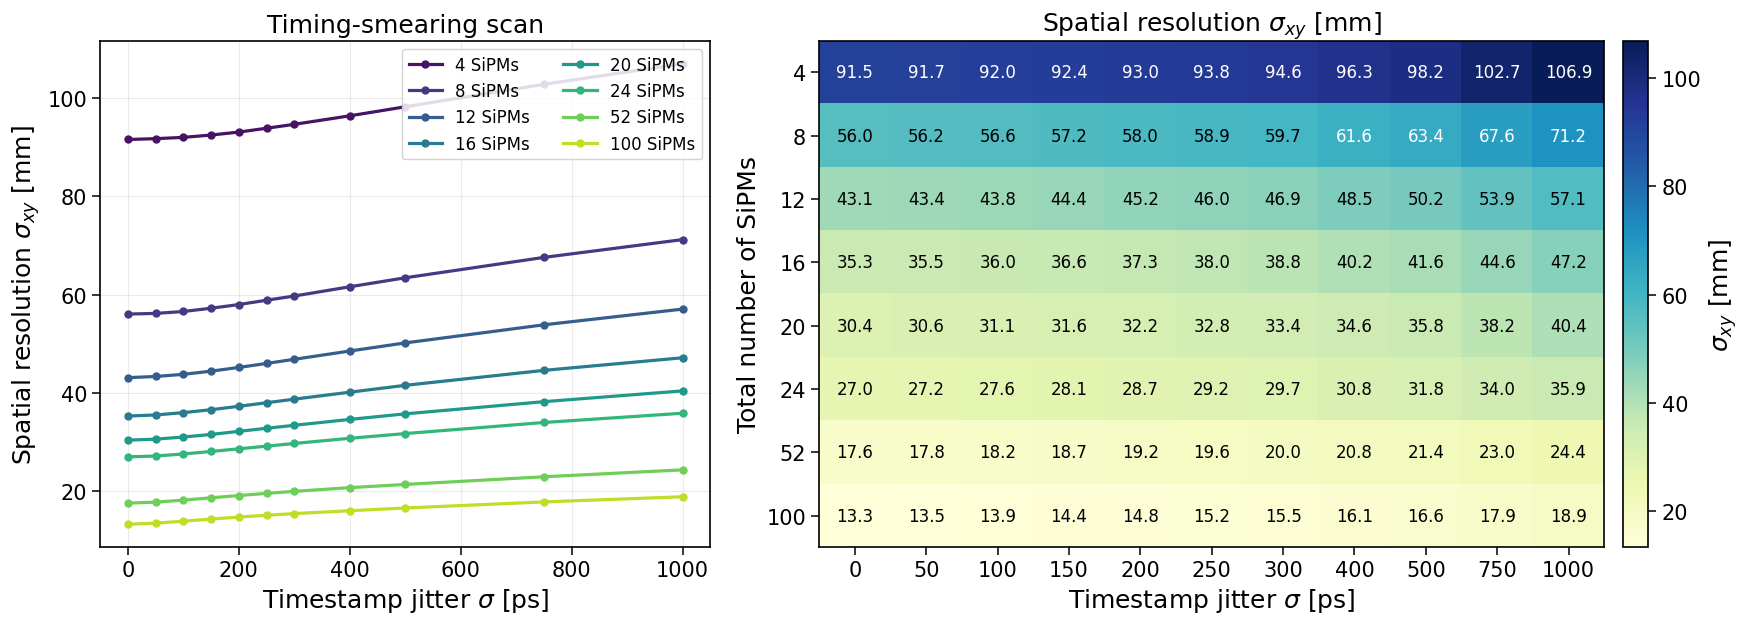

In [1]:
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

BASE=Path('/Volumes/ExtremeSSD/Software/PlasticMuonTiming/run/BatchStudies_1000')
OUT=BASE/'sipm_figures'; OUT.mkdir(exist_ok=True)
edges=[0,1,2,3,4,5,12,24]; counts=np.array([4+4*e for e in edges])

summary=[]; scans=[]
for e in edges:
    f=BASE/f'output_edge{e}_spatiotemporal'
    with open(f/'spatiotemporal_reconstruction_summary.csv') as x:
        r=next(r for r in csv.DictReader(x) if r['method']=='A + t1+t2+t3 ExtraTrees')
        summary.append({k:float(v) for k,v in r.items() if k!='method'})
    with open(f/'true_detector_timing_resolution_scan.csv') as x:
        scans.append({int(r['sigma_t_ps']):float(r['sigma_xy_mm']) for r in csv.DictReader(x)})

sigma=np.array([r['sigma_xy_mm'] for r in summary])

# Reference-figure style
plt.rcParams.update({
    'font.family':'DejaVu Sans','font.size':15,
    'axes.labelsize':18,'axes.titlesize':18,
    'xtick.labelsize':15,'ytick.labelsize':15,
    'legend.fontsize':14,'axes.linewidth':1.2,
    'axes.spines.top':True,'axes.spines.right':True,
    'xtick.major.width':1.1,'ytick.major.width':1.1,
    'xtick.major.size':6,'ytick.major.size':6,
    'figure.facecolor':'white','axes.facecolor':'white',
    'pdf.fonttype':42
})

def save(fig,n):
    fig.savefig(OUT/f'{n}.png',dpi=190,bbox_inches='tight')
    # fig.savefig(OUT/f'{n}.pdf',bbox_inches='tight')
    plt.show()

# ============================================================
# Figure 1
# ============================================================
fig,(a,b)=plt.subplots(1,2,figsize=(15,6))

for k,l,c,m in [('R90_mm','$R_{90}$','#ff7f0e','^'),
                ('R68_mm','$R_{68}$','#2ca02c','s'),
                ('sigma_xy_mm','$\\sigma_{xy}$','#1f77b4','o')]:
    y=[r[k] for r in summary]
    a.plot(counts,y,m+'-',lw=2.5,ms=7,color=c,label=l)
    if k=='sigma_xy_mm':
        for x,v in zip(counts,y):
            a.annotate(f'{v:.1f}',(x,v),xytext=(0,-20),
                       textcoords='offset points',ha='center',fontsize=12,color=c)

a.set(xlabel='Total number of SiPMs',ylabel='Position error [mm]',
      xticks=counts,title='Spatial resolution and containment')
a.grid(alpha=.25); a.legend(loc='upper right',frameon=True,fancybox=True,framealpha=.85)

g=-np.diff(sigma); x=np.arange(len(g))
bars=b.bar(x,g,width=.7,edgecolor='#1f77b4',facecolor='#1f77b4',linewidth=2.2)
for i,(bar,v) in enumerate(zip(bars,g)):
    b.text(bar.get_x()+bar.get_width()/2,v+.5,
           f'{v:.1f} mm\n({100*v/sigma[i]:.1f}%)',
           ha='center',fontsize=12)

b.set(xticks=x,xticklabels=[f'{counts[i]}→{counts[i+1]}' for i in x],
      xlabel='SiPM count change',ylabel='Reduction in $\\sigma_{xy}$ [mm]',
      title='Gain from additional sensors')
b.tick_params(axis='x',rotation=30); b.grid(axis='y',alpha=.25)

fig.tight_layout()
save(fig,'01_sipm_resolution_and_gains')


# ============================================================
# Figure 2
# ============================================================
fig,(a,b)=plt.subplots(1,2,figsize=(18,6.5),gridspec_kw={'width_ratios':[1,1.55]})

colors=plt.cm.viridis(np.linspace(.05,.9,len(counts)))
for n,s,c in zip(counts,scans,colors):
    x=sorted(s)
    a.plot(x,[s[t] for t in x],'o-',ms=5,lw=2.3,color=c,label=f'{n} SiPMs')

a.set(xlabel='Timestamp jitter $\\sigma$ [ps]',
      ylabel='Spatial resolution $\\sigma_{xy}$ [mm]',
      title='Timing-smearing scan')
a.grid(alpha=.25)
a.legend(frameon=True,fancybox=True,framealpha=.85,ncol=2,fontsize=12)

t=sorted(set.intersection(*map(lambda s:set(s),scans)))
M=np.array([[s[x] for x in t] for s in scans])
im=b.imshow(M,cmap='YlGnBu',aspect='auto')

cb=fig.colorbar(im,ax=b,pad=.02)
cb.set_label('$\\sigma_{xy}$ [mm]',fontsize=18)
cb.ax.tick_params(labelsize=15)

mid=(M.min()+M.max())/2
for i in range(len(counts)):
    for j in range(len(t)):
        b.text(j,i,f'{M[i,j]:.1f}',ha='center',va='center',
               color='white' if M[i,j]>mid else 'black',fontsize=12)

b.set(xticks=range(len(t)),xticklabels=t,
      yticks=range(len(counts)),yticklabels=counts,
      xlabel='Timestamp jitter $\\sigma$ [ps]',
      ylabel='Total number of SiPMs',
      title='Spatial resolution $\\sigma_{xy}$ [mm]')

fig.tight_layout()
save(fig,'02_sipm_timing_precision')